# Agentic RAG 단기 기억(Short-term Memory) 실습   
— `PostgresSaver` 체크포인터

LangGraph는 대화 기록을 DB에 저장ㆍ복원하는 역할을 **체크포인터(Checkpointer)**로 대신 해준다.
이 노트북은 [`2-1.short_term_memory_manual.ipynb`](2-1.short_term_memory_manual.ipynb)에서 `load_memory`/`save_memory` 노드로 직접 구현한 것과 **똑같은 시나리오**를, LangGraph가 PostgreSQL에 저장해주는 내장 기능인 `PostgresSaver`로 다시 구현한다. 두 노트북은 서로 **독립적으로** 실행할 수 있다.

### 사용 단계

1. **패키지 설치** 
- `uv add langgraph-checkpoint-postgres "psycopg[binary]"` (주의: `psycopg2`가 아니라 **psycopg 3**을 쓴다)
2. **연결 문자열(DSN) 준비** 
- `common.postgres.get_postgres_dsn()`
3. **체크포인터 생성 + 테이블 준비** 
- `PostgresSaver.from_conn_string(dsn)`으로 만들고, `setup()`을 **최초 1회** 호출하면 `checkpoints` 등 필요한 테이블이 자동 생성된다
4. **그래프에 연결** 
- `builder.compile(checkpointer=checkpointer)`
5. **실행** 
- `graph.invoke(상태, config={"configurable": {"thread_id": "..."}})`처럼 `thread_id`를 넘기면, 같은 `thread_id`의 이전 State를 체크포인터가 **자동으로 불러와 이어준다** — `load_memory`/`save_memory`에 해당하는 코드가 전혀 필요 없다

> 사전 조건: PostgreSQL 실행 중(`cd docker-postgresql && docker compose up -d`) + Qdrant 실행 중(`cd docker-qdrant && docker compose up -d`) + 색인 완료(`uv run python -m rag.indexer`)


## 0. 환경 설정


In [1]:
from typing import TypedDict

from IPython.display import Image, Markdown, display
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph

from common.ai_model import get_llm_model
from common.config import RERANK_TOP_N, RETRIEVAL_TOP_K
from common.postgres import get_postgres_connection
from rag.chunker import format_article_label
from rag.reranker import rerank
from rag.retriever import RetrievedChunk, retrieve


In [2]:
# 동일 질문 반복 호출 시 토큰 비용을 아끼기 위한 인메모리 LLM 캐시
# (프로세스 내 캐시이므로 노트북 재시작 시 초기화됨)
set_llm_cache(InMemoryCache())

# 답변 생성용 LLM
answer_llm = get_llm_model(max_tokens=1024)


### 공통 헬퍼 (`1-1.agentic_rag.ipynb`과 동일)

- `search_law`: Hybrid 검색(Dense+BM25, RRF) → LLM Rerank
- `format_context` / `format_sources`: 검색 결과를 LLM 입력용 / 출력용 문자열로 변환
- `show_graph`: 그래프 구조 시각화


In [3]:
def search_law(query: str) -> list[RetrievedChunk]:
    """rag 모듈로 Hybrid 검색 후 Rerank해 상위 N개 조문을 반환한다."""
    candidates = retrieve(query, top_k=RETRIEVAL_TOP_K, use_hybrid=True)
    return rerank(query, candidates, top_n=RERANK_TOP_N)


def format_context(documents: list[RetrievedChunk]) -> str:
    """검색된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc.chunk.text for doc in documents)


def format_sources(documents: list[RetrievedChunk]) -> str:
    """검색된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc.chunk.article_no)
        title = f"({doc.chunk.article_title})" if doc.chunk.article_title else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"


def show_graph(graph) -> None:
    """그래프 구조를 PNG로 표시하고, 실패하면 Mermaid 텍스트로 출력한다."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


### 공통 프롬프트

`2-1` 노트북의 `MEMORY_ANSWER_SYSTEM_PROMPT`와 같은 역할이다. 거기서는 이전 대화를 `<history>` 문자열로 직접 합쳐 넣었지만, 여기서는 `messages` 리스트 자체를 대화 턴으로 그대로 전달한다.


In [4]:
MEMORY_ANSWER_SYSTEM_PROMPT = (
    "너는 인공지능기본법 QA 어시스턴트다. 이전 대화 흐름을 참고해 "
    "이번 질문의 의도(지시어가 가리키는 대상 등)를 파악하라. "
    "답변은 반드시 <context>의 조문만 근거로 하고, 근거 조문(예: 제2조)을 끝에 명시하라. "
    "context에 없는 내용은 모른다고 답하라."
)

In [5]:
from typing import Annotated

from langchain_core.messages import AIMessage
from langgraph.checkpoint.postgres import PostgresSaver
from langgraph.graph.message import add_messages

from common.postgres import get_postgres_dsn


---
## 1. 체크포인터 준비

`PostgresSaver.from_conn_string(dsn)`은 보통 `with ... as checkpointer:` 형태로 쓰지만,  
노트북은 여러 셀에 걸쳐 같은 체크포인터를 계속 쓰므로 **수동으로 연다**.  
노트북 마지막에서 명시적으로 닫아준다 (`checkpointer_cm.__exit__(...)`).  


In [6]:
checkpointer_cm = PostgresSaver.from_conn_string(get_postgres_dsn())
checkpointer = checkpointer_cm.__enter__()
checkpointer.setup()  # 최초 1회: checkpoints 등 테이블 자동 생성
print("체크포인터 준비 완료")


체크포인터 준비 완료


---
## 2. State / Node 정의

`messages` 필드에 `Annotated[list, add_messages]`를 쓰면, 노드가 반환한 메시지를 **덮어쓰지 않고 기존 메시지 뒤에 이어붙인다.** 체크포인터가 이전 턴의 `messages`를 미리 복원해 두기 때문에, `state["messages"]`를 참고하기만 하면 직접 DB를 조회하지 않아도 이전 대화를 알 수 있다.

> **`documents`는 `RetrievedChunk` 객체가 아니라 `dict`로 저장한다.** `PostgresSaver`는 State 전체를 msgpack으로 직렬화하는데, 우리가 만든 `RetrievedChunk`/`LawChunk` 같은 커스텀 클래스를 그대로 저장하면 복원할 때 `Deserializing unregistered type ...` 경고가 뜬다. `article_no`/`article_title`/`text`만 담은 평범한 `dict`로 변환해서 저장하면, msgpack이 기본으로 다루는 표준 타입만 쓰게 되어 경고 없이 저장ㆍ복원된다.


In [7]:
def to_source_payload(documents: list[RetrievedChunk]) -> list[dict]:
    """RetrievedChunk(커스텀 객체)를 체크포인터가 그대로 저장할 수 있는 dict로 변환한다."""
    return [
        {
            "article_no": doc.chunk.article_no,
            "article_title": doc.chunk.article_title,
            "text": doc.chunk.text,
        }
        for doc in documents
    ]

def cp_format_context(documents: list[dict]) -> str:
    """dict로 변환된 조문 텍스트를 LLM context 문자열로 합친다."""
    return "\n\n".join(doc["text"] for doc in documents)

def cp_format_sources(documents: list[dict]) -> str:
    """dict로 변환된 조문을 '제N조(제목)' 목록 문자열로 만든다."""
    labels = []
    for doc in documents:
        label = format_article_label(doc["article_no"])
        title = f"({doc['article_title']})" if doc["article_title"] else ""
        labels.append(f"{label}{title}")
    return ", ".join(dict.fromkeys(labels)) or "(없음)"

class CheckpointState(TypedDict):
    question: str
    documents: list[dict]  # RetrievedChunk가 아니라 직렬화하기 쉬운 dict로 저장한다
    messages: Annotated[list, add_messages]  # 체크포인터가 자동으로 이어붙여줌
    answer: str

def cp_retrieve_node(state: CheckpointState) -> dict:
    documents = search_law(state["question"])
    return {"documents": to_source_payload(documents)}

def cp_generate_node(state: CheckpointState) -> dict:
    context = cp_format_context(state["documents"])
    question_message = HumanMessage(
        content=f"질문: {state['question']}\n\n<context>\n{context}\n</context>"
    )
    # state["messages"]에는 체크포인터가 복원해 둔 이전 턴의 대화가 이미 들어있다
    response = answer_llm.invoke([
        SystemMessage(content=MEMORY_ANSWER_SYSTEM_PROMPT),
        *state["messages"],
        question_message,
    ])
    answer_message = AIMessage(content=response.content)
    return {
        "answer": response.content,
        "messages": [question_message, answer_message],  # add_messages가 뒤에 이어붙인다
    }


---
## 3. 그래프 조립 — `load_memory`/`save_memory` 노드가 없다


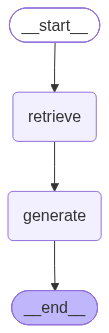

In [8]:
builder = StateGraph(CheckpointState)
builder.add_node("retrieve", cp_retrieve_node)
builder.add_node("generate", cp_generate_node)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", END)

checkpoint_graph = builder.compile(
  checkpointer=checkpointer
  )
show_graph(checkpoint_graph)


> **참고 — `documents`를 dict로 저장하는 이유**
> 이전 버전에서는 `documents`에 `RetrievedChunk` 객체를 그대로 넣어서, 두 번째 질문부터 `Deserializing unregistered type ...` 경고가 떴다. 커스텀 클래스를 msgpack이 모르기 때문이다. 바로 위 2번 섹션에서 `to_source_payload`로 `dict`로 변환해 저장하도록 바꿨고, 그 결과 `checkpoint_blobs.blob`에는 표준 타입만 직렬화되어 경고 없이 정상적으로 저장ㆍ복원된다.


---
## 4. 실행 — `thread_id`로 세션 구분

`session_id` 대신 `thread_id`를 쓴다는 것만 다르고, 같은 스레드는 기억하고 다른 스레드는 기억하지 못하는 동작은 `2-1` 노트북의 4번 섹션과 같은 방식으로 확인한다.


In [9]:
def run_checkpoint(graph, thread_id: str, question: str) -> dict:
    """thread_id로 그래프를 실행하고 근거 조문ㆍ답변을 출력한 뒤 최종 State를 반환한다."""
    print(f"[{thread_id}] Q. {question}")
    config = {"configurable": {"thread_id": thread_id}}
    result = graph.invoke({"question": question}, config=config)
    print("근거 조문:", cp_format_sources(result["documents"]))
    display(Markdown(result["answer"]))
    return result


**① 첫 질문** — `cp-session-1` 스레드로 질문한다. 이전 기록이 없으므로 `messages`가 빈 리스트로 시작한다.


In [10]:
_ = run_checkpoint(checkpoint_graph, "cp-session-1", "고영향 인공지능이란 무엇인가요?")


[cp-session-1] Q. 고영향 인공지능이란 무엇인가요?
근거 조문: 제제1조조(목적)


제공된 <context>에는 **“고영향 인공지능”의 정의**가 나오지 않습니다. 따라서 이 자료만으로는 고영향 인공지능이 무엇인지 답할 수 없습니다.  

근거: <context>에 관련 정의 조문 없음

**② 후속 질문(같은 스레드)** — `load_memory` 노드를 만들지 않았는데도, 체크포인터가 ①의 `messages`를 복원해주므로 '그것'이 무엇을 가리키는지 이해할 수 있어야 한다.


In [11]:
_ = run_checkpoint(checkpoint_graph, "cp-session-1", "그것을 만든 사업자는 어떤 책무를 지나요?")


[cp-session-1] Q. 그것을 만든 사업자는 어떤 책무를 지나요?


근거 조문: 제제1조조(목적)


제공된 <context>에는 **“그것”이 가리키는 대상**이나, **그것을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 이 자료만으로는 어떤 책무를 지는지 알 수 없습니다.  

근거: <context>에 관련 조문 없음

**③ 같은 질문을 다른 스레드(`cp-session-2`)에서** — 체크포인터에 이 스레드의 기록이 없으므로 `messages`가 빈 리스트로 시작한다. 스레드별로 기억이 분리된다는 것을 보여준다.


In [12]:
_ = run_checkpoint(checkpoint_graph, "cp-session-2", "그것을 만든 사업자는 어떤 책무를 지나요?")


[cp-session-2] Q. 그것을 만든 사업자는 어떤 책무를 지나요?
근거 조문: 제제1조조(목적)


제공된 <context>에는 인공지능을 만든 사업자의 책무에 관한 조문이 없습니다. 따라서 어떤 책무를 지는지 알 수 없습니다.

근거 조문: 없음

---
## 5. 저장된 State 직접 들여다보기

`graph.get_state(config)`로, 우리가 SQL을 한 줄도 쓰지 않았는데도 PostgreSQL에 저장되어 있던 `messages`를 그대로 복원해 확인할 수 있다.


In [13]:
snapshot = checkpoint_graph.get_state({"configurable": {"thread_id": "cp-session-1"}})

print("cp-session-1에 저장된 메시지 수:", len(snapshot.values["messages"]))
for message in snapshot.values["messages"]:
    print(f"- {type(message).__name__}: {message.content[:40]}...")


cp-session-1에 저장된 메시지 수: 4
- HumanMessage: 질문: 고영향 인공지능이란 무엇인가요?

<context>
이 법은 인공...
- AIMessage: 제공된 <context>에는 **“고영향 인공지능”의 정의**가 나오지 ...
- HumanMessage: 질문: 그것을 만든 사업자는 어떤 책무를 지나요?

<context>
이...
- AIMessage: 제공된 <context>에는 **“그것”이 가리키는 대상**이나, **그...


---
## 6. 체크포인터 연결 종료

`__enter__()`로 수동으로 열었으니, 노트북을 마치기 전에 명시적으로 닫아준다.


In [14]:
checkpointer_cm.__exit__(None, None, None)
print("체크포인터 연결 종료")

체크포인터 연결 종료


## PostgreSQL에 저장된 데이터 확인

In [15]:
import psycopg

from common.postgres import get_postgres_dsn

THREAD_ID = "cp-session-1"

# PostgreSQL에 저장된 채널별 최신 데이터 확인
with psycopg.connect(get_postgres_dsn()) as conn:
    with conn.cursor() as cur:
        cur.execute("""
            SELECT DISTINCT ON (channel)
                channel,
                type,
                OCTET_LENGTH(blob) AS blob_size
            FROM public.checkpoint_blobs
            WHERE thread_id = %s
              AND checkpoint_ns = ''
            ORDER BY channel, version DESC
        """, (THREAD_ID,))

        rows = cur.fetchall()

print("=== PostgreSQL 저장 데이터 ===")

for channel, data_type, size in rows:
    print(f"{channel:12} | {data_type:10} | {size} bytes")

=== PostgreSQL 저장 데이터 ===
documents    | msgpack    | 322 bytes
messages     | msgpack    | 2008 bytes
__start__    | msgpack    | 69 bytes


## blob 데이터 역직렬화

In [16]:
from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer

# LangGraph 기본 직렬화기
serializer = JsonPlusSerializer()

# messages 채널의 최신 blob 조회
with psycopg.connect(get_postgres_dsn()) as conn:
    with conn.cursor() as cur:
        cur.execute("""
            SELECT type, blob
            FROM public.checkpoint_blobs
            WHERE thread_id = %s
              AND checkpoint_ns = ''
              AND channel = 'messages'
            ORDER BY version DESC
            LIMIT 1
        """, (THREAD_ID,))

        row = cur.fetchone()

if row and row[1] is not None:
    data_type, blob = row

    print("=== 직렬화된 데이터 ===")
    print("저장 형식:", data_type)
    print("바이너리 크기:", len(blob), "bytes")

    # 바이너리 -> Python 객체
    messages = serializer.loads_typed(
        (data_type, bytes(blob))
    )

    print("\n=== 역직렬화된 메시지 ===")

    for i, message in enumerate(messages, start=1):
        print(f"\n[{i}] {type(message).__name__}")
        print(message.content)
else:
    print("저장된 메시지가 없습니다.")

=== 직렬화된 데이터 ===
저장 형식: msgpack
바이너리 크기: 2008 bytes

=== 역직렬화된 메시지 ===

[1] HumanMessage
질문: 고영향 인공지능이란 무엇인가요?

<context>
이 법은 인공지능의 건전한 발전과 신뢰 기반 조성에 필요한 기본적인 사항을 규정함으로써 국민의 권익과 존엄성을 보호하고 국민의 삶의 질 향상과 국가경쟁력을 강화하는 데 이바지함을 목적으로 한다.
</context>

[2] AIMessage
제공된 <context>에는 **“고영향 인공지능”의 정의**가 나오지 않습니다. 따라서 이 자료만으로는 고영향 인공지능이 무엇인지 답할 수 없습니다.  

근거: <context>에 관련 정의 조문 없음

[3] HumanMessage
질문: 그것을 만든 사업자는 어떤 책무를 지나요?

<context>
이 법은 인공지능의 건전한 발전과 신뢰 기반 조성에 필요한 기본적인 사항을 규정함으로써 국민의 권익과 존엄성을 보호하고 국민의 삶의 질 향상과 국가경쟁력을 강화하는 데 이바지함을 목적으로 한다.
</context>

[4] AIMessage
제공된 <context>에는 **“그것”이 가리키는 대상**이나, **그것을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 이 자료만으로는 어떤 책무를 지는지 알 수 없습니다.  

근거: <context>에 관련 조문 없음


## Checkpointer로 전체 State 복원

In [17]:
from langgraph.checkpoint.postgres import PostgresSaver

config = {
    "configurable": {
        "thread_id": THREAD_ID
    }
}

# 6번에서 연결을 종료했으므로 새 연결 사용
with PostgresSaver.from_conn_string(get_postgres_dsn()) as saver:

    # 저장된 최신 Checkpoint 복원
    saved = saver.get_tuple(config)

    if saved is None:
        print("저장된 Checkpoint가 없습니다.")
    else:
        state = saved.checkpoint["channel_values"]

        print("=== 복원된 State ===")

        print("\n[질문]")
        print(state.get("question", ""))

        print("\n[답변]")
        print(state.get("answer", ""))

        print("\n[대화 기록]")
        for message in state.get("messages", []):
            print(
                f"{type(message).__name__}: "
                f"{message.content}"
            )

        print("\n[검색 문서]")
        for doc in state.get("documents", []):
            print(
                f"제{doc['article_no']}조 "
                f"{doc['article_title']}"
            )

=== 복원된 State ===

[질문]
그것을 만든 사업자는 어떤 책무를 지나요?

[답변]
제공된 <context>에는 **“그것”이 가리키는 대상**이나, **그것을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 이 자료만으로는 어떤 책무를 지는지 알 수 없습니다.  

근거: <context>에 관련 조문 없음

[대화 기록]
HumanMessage: 질문: 고영향 인공지능이란 무엇인가요?

<context>
이 법은 인공지능의 건전한 발전과 신뢰 기반 조성에 필요한 기본적인 사항을 규정함으로써 국민의 권익과 존엄성을 보호하고 국민의 삶의 질 향상과 국가경쟁력을 강화하는 데 이바지함을 목적으로 한다.
</context>
AIMessage: 제공된 <context>에는 **“고영향 인공지능”의 정의**가 나오지 않습니다. 따라서 이 자료만으로는 고영향 인공지능이 무엇인지 답할 수 없습니다.  

근거: <context>에 관련 정의 조문 없음
HumanMessage: 질문: 그것을 만든 사업자는 어떤 책무를 지나요?

<context>
이 법은 인공지능의 건전한 발전과 신뢰 기반 조성에 필요한 기본적인 사항을 규정함으로써 국민의 권익과 존엄성을 보호하고 국민의 삶의 질 향상과 국가경쟁력을 강화하는 데 이바지함을 목적으로 한다.
</context>
AIMessage: 제공된 <context>에는 **“그것”이 가리키는 대상**이나, **그것을 만든 사업자의 책무**에 관한 내용이 없습니다. 따라서 이 자료만으로는 어떤 책무를 지는지 알 수 없습니다.  

근거: <context>에 관련 조문 없음

[검색 문서]
제제1조조 목적


---
## 정리

| 단계 | 내용 |
|---|---|
| 1 | `PostgresSaver.from_conn_string(dsn)` + `setup()`으로 체크포인터 준비 |
| 2 | `messages: Annotated[list, add_messages]`로 State 정의, `load_memory`/`save_memory` 없이 Node 작성 |
| 3 | `builder.compile(checkpointer=checkpointer)`로 그래프 조립 |
| 4 | 같은 `thread_id`는 이전 대화를 기억하고, 다른 `thread_id`는 기억하지 못함을 확인 |
| 5 | `graph.get_state(config)`로 저장된 State를 SQL 없이 직접 조회 |
| 6 | 체크포인터 연결 종료 |

| | [`2-1.short_term_memory_manual.ipynb`](2-1.short_term_memory_manual.ipynb) | 이 노트북(`PostgresSaver`) |
|---|---|---|
| 저장 단위 | 내가 고른 필드(질문/답변 텍스트) | 그래프 State 전체 |
| 저장/조회 코드 | 직접 작성 (`load_memory`/`save_memory`) | 불필요 (`checkpointer=...`만 넘기면 됨) |
| 구분 키 | `session_id` (내가 만든 컬럼) | `thread_id` (LangGraph 표준 개념) |
| 테이블 스키마 | 내가 설계 | `PostgresSaver`가 자동 생성 |
| 투명성 | 어떤 SQL이 도는지 전부 보임 | 내부 동작은 블랙박스 |

`2-1` 노트북에서 원리를 먼저 구현해봤다면, 이 노트북의 `PostgresSaver`가 내부적으로 무엇을 대신해주고 있는지 명확히 알 수 있다.
